In [6]:
import numpy as np
import pandas as pd

In [7]:
PATH = "../data/raw/anemia_dataset.xlsx"
dataset = pd.read_excel(PATH)

In [8]:
print(f"\033[32mColunas:\033[0m {dataset.columns.tolist()}")

Colunas: ['GENDER', 'WBC', 'NE#', 'LY#', 'MO#', 'EO#', 'BA#', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW', 'PLT', 'MPV', 'PCT', 'PDW', 'SD', 'SDTSD', 'TSD', 'FERRITTE', 'FOLATE', 'B12', 'All_Class', 'HGB_Anemia_Class', 'Iron_anemia_Class', 'Folate_anemia_class', 'B12_Anemia_class']


In [9]:
print(f"\033[32mDimensão:\033[0m {dataset.shape}")

Dimensão: (15300, 29)


In [10]:
print(f"\033[32mInformações adicionais:\033[0m")
dataset.info()

Informações adicionais:
<class 'pandas.DataFrame'>
RangeIndex: 15300 entries, 0 to 15299
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   GENDER               15300 non-null  int64  
 1   WBC                  15300 non-null  float64
 2   NE#                  15300 non-null  float64
 3   LY#                  15300 non-null  float64
 4   MO#                  15300 non-null  float64
 5   EO#                  15300 non-null  float64
 6   BA#                  15300 non-null  float64
 7   RBC                  15300 non-null  float64
 8   HGB                  15300 non-null  float64
 9   HCT                  15300 non-null  float64
 10  MCV                  15300 non-null  float64
 11  MCH                  15300 non-null  float64
 12  MCHC                 15300 non-null  float64
 13  RDW                  15300 non-null  float64
 14  PLT                  15300 non-null  float64
 15  MPV                  15

In [11]:
print(f"\033[32mEstatísticas:\033[0m")
print(dataset.describe())

Estatísticas:
             GENDER           WBC           NE#           LY#           MO#  \
count  15300.000000  15300.000000  15300.000000  15300.000000  15300.000000   
mean       0.321634      8.101484      5.071174      2.238544      0.571611   
std        0.467119      4.377038      3.510666      1.866808      0.319411   
min        0.000000      0.570000      0.030000      0.110000      0.000000   
25%        0.000000      6.100000      3.399750      1.640000      0.412000   
50%        0.000000      7.490000      4.420000      2.110000      0.530000   
75%        1.000000      9.220000      5.880000      2.630000      0.670000   
max        1.000000    246.700000    197.200000     89.600000     18.510000   

                EO#           BA#           RBC           HGB           HCT  \
count  15300.000000  15300.000000  15300.000000  15300.000000  15300.000000   
mean       0.155692      0.064874      4.689159     12.781204     38.958891   
std        0.199153      0.223069    

In [12]:
print(f"\033[32mPrimeiras linhas:\033[0m")
dataset.head()

Primeiras linhas:


,GENDER,WBC,NE#,LY#,MO#,EO#,BA#,RBC,HGB,HCT,...,SDTSD,TSD,FERRITTE,FOLATE,B12,All_Class,HGB_Anemia_Class,Iron_anemia_Class,Folate_anemia_class,B12_Anemia_class
0,1,10.63,6.31,2.79,0.91,0.56,0.06,4.31,12.7,37.6,...,248.90,40.176778,194.00,5.06,178.2,4,0,0,0,1
1,1,5.08,2.50,1.87,0.43,0.26,0.02,4.34,12.8,36.9,...,348.48,33.482553,57.37,9.88,197.7,4,0,0,0,1
2,1,13.68,9.40,2.69,1.55,0.03,0.01,3.18,9.4,27.5,...,357.27,20.144429,114.20,8.37,143.0,4,0,0,0,1
3,1,5.60,3.94,0.83,0.54,0.26,0.03,3.35,10.5,31.4,...,360.60,27.731559,214.20,6.39,139.9,4,0,0,0,1
4,1,3.57,2.03,1.25,0.10,0.18,0.01,1.31,5.1,14.3,...,223.28,78.860623,303.40,4.30,50.0,4,0,0,0,1


In [13]:
print(f"\033[32mLinhas duplicadas:\033[0m {dataset.duplicated().sum()}")

Linhas duplicadas: 88


In [14]:
without_anemia = dataset[dataset.All_Class == 0].shape[0]
anemia_hgb = dataset[dataset.HGB_Anemia_Class == 1].shape[0]
iron_deficiency_anemia = dataset[dataset.Iron_anemia_Class == 1].shape[0]
folato_deficiency_anemia = dataset[dataset.Folate_anemia_class == 1].shape[0]
b12_deficiency_anemia = dataset[dataset.B12_Anemia_class == 1].shape[0]

anemics = (
    anemia_hgb
    + iron_deficiency_anemia
    + folato_deficiency_anemia
    + b12_deficiency_anemia
)

print(f"\033[32mSem anemia:\033[0m {without_anemia}")
print(f"Anêmicos HGB: {anemia_hgb}")
print(f"Anêmicos por deficiência de ferro: {iron_deficiency_anemia}")
print(f"Anêmicos por deficiência de folato: {folato_deficiency_anemia}")
print(f"Anêmicos por deficiência de vitamina B12: {b12_deficiency_anemia}")
print(f"\033[32mTotal anêmicos:\033[0m {anemics}")

Sem anemia: 9747
Anêmicos HGB: 1019
Anêmicos por deficiência de ferro: 4182
Anêmicos por deficiência de folato: 153
Anêmicos por deficiência de vitamina B12: 199
Total anêmicos: 5553


## Gráficos de Análise

### Desbalanceamento de Classes

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

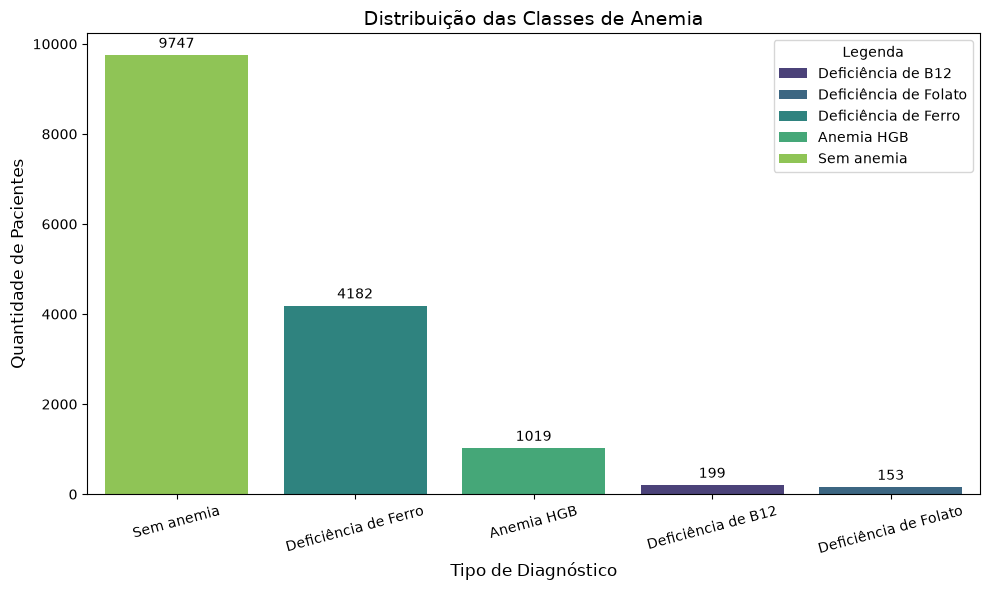

In [16]:
nomes_classes = {
    0: "Sem anemia",
    1: "Anemia HGB",
    2: "Deficiência de Ferro",
    3: "Deficiência de Folato",
    4: "Deficiência de B12",
}

classes_mapeadas = dataset["All_Class"].map(nomes_classes)

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    x=classes_mapeadas,
    hue=classes_mapeadas,
    palette="viridis",
    order=classes_mapeadas.value_counts().index,
    legend=True,
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Distribuição das Classes de Anemia", fontsize=14)
plt.xlabel("Tipo de Diagnóstico", fontsize=12)
plt.ylabel("Quantidade de Pacientes", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Legenda")
plt.tight_layout()
plt.show()

In [17]:
import ipywidgets as widgets
from IPython.display import display

cols = dataset.select_dtypes(include=["float64"]).columns.tolist()


def plotar_exame(col):
    # 1. Cálculo dos limites (IQR)
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    qtd_outliers = ((dataset[col] < limite_inf) | (dataset[col] > limite_sup)).sum()
    pct_outliers = (qtd_outliers / len(dataset)) * 100

    fig, ax = plt.subplots(figsize=(10, 3.5))

    sns.boxplot(
        data=dataset,
        x=col,
        ax=ax,
        color="#4C72B0",
        flierprops=dict(marker="o", markerfacecolor="red", markersize=5),
    )

    ax.axvline(
        limite_inf,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"Limite Inf: {limite_inf:.2f}",
    )
    ax.axvline(
        limite_sup,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"Limite Sup: {limite_sup:.2f}",
    )

    ax.set_title(
        f"Distribuição e Outliers: {col} ({qtd_outliers} casos |"
        f" {pct_outliers:.1f}%)",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel(col, fontsize=10)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

    resumo = pd.DataFrame(
        [
            {
                "Exame": col,
                "Mínimo Real": round(dataset[col].min(), 2),
                "Limite Inferior (IQR)": round(limite_inf, 2),
                "Mediana": round(dataset[col].median(), 2),
                "Limite Superior (IQR)": round(limite_sup, 2),
                "Máximo Real": round(dataset[col].max(), 2),
                "Total Outliers": qtd_outliers,
            }
        ]
    )
    display(resumo)


seletor = widgets.Dropdown(options=cols, value=cols[0], description="Exame:")
out = widgets.interactive_output(plotar_exame, {"col": seletor})

display(seletor, out)

ModuleNotFoundError: No module named 'ipywidgets'